## Notebook for Test Purposes
This notebooks has been used for test purposes before implementing or writing a collection and analysis script. 

The notebook includes the following:
- example embedded API routes
- analysis of the number of collected tweets, in order to find out how many tweets have been collected and how many tweets are missing
- test for getting API call
- test for collecting missing tweets
- method for getting the sample tweet data for the analysis
- methods for the visualizations that have been used in the thesis and the presentations

### Example Embedded API Route to hydrate tweets

In [2]:
import requests

url = "https://cdn.syndication.twimg.com/tweet-result"

querystring = {"id":"1664013858292346881","lang":"en", "token":"x"}

payload = ""
headers = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64; rv:109.0) Gecko/20100101 Firefox/114.0",
    "Accept": "*/*",
    "Accept-Language": "en-US,en;q=0.5",
    "Accept-Encoding": "gzip, deflate, br",
    "Origin": "https://platform.twitter.com",
    "Connection": "keep-alive",
    "Referer": "https://platform.twitter.com/",
    "Sec-Fetch-Dest": "empty",
    "Sec-Fetch-Mode": "cors",
    "Sec-Fetch-Site": "cross-site",
    "Pragma": "no-cache",
    "Cache-Control": "no-cache",
    "TE": "trailers"
}

response = requests.request("GET", url, data=payload, headers=headers, params=querystring)

print(response.text)

{"__typename":"Tweet","in_reply_to_screen_name":"Sol__Yumruk","in_reply_to_status_id_str":"1663984481437401105","in_reply_to_user_id_str":"2917028536","lang":"tr","favorite_count":0,"created_at":"2023-05-31T20:59:54.000Z","display_text_range":[13,51],"entities":{"hashtags":[],"urls":[],"user_mentions":[{"id_str":"2917028536","indices":[0,12],"name":"Sol Yumruk","screen_name":"Sol__Yumruk"}],"symbols":[]},"id_str":"1664013858292346881","text":"@Sol__Yumruk 2 sene çok.Bu gidişle 6 ayı zor görür.","user":{"id_str":"3391907170","name":"Gül","profile_image_url_https":"https://pbs.twimg.com/profile_images/1654189008019247121/QLFPdGEr_normal.jpg","screen_name":"gul741502","verified":false,"is_blue_verified":false,"profile_image_shape":"Circle"},"edit_control":{"edit_tweet_ids":["1664013858292346881"],"editable_until_msecs":"1685568594000","is_edit_eligible":false,"edits_remaining":"5"},"conversation_count":0,"news_action_type":"conversation","parent":{"lang":"tr","reply_count":4472,"retweet_c

### Analysis of the collected tweet data
These are the steps to have a general overview of the collected tweet data. 

In [1]:
import glob

# Replace 'your_main_folder_path' with the path to your main folder
your_main_folder_path = '../data/output/**/*.csv'
csv_files = glob.glob(your_main_folder_path, recursive=True)
number_of_csv_files = len(csv_files)
print(f"Total number of CSV files: {number_of_csv_files}")


Total number of CSV files: 25779


In [ ]:
import pandas as pd

def check_non_empty_text(file_path):
    try:
        df = pd.read_csv(file_path, usecols=['text'])
        if not df['text'].dropna().empty:
            return True
    except Exception as e:
        print(f"Error processing file {file_path}: {e}")
    return False

non_empty_text_files = sum(check_non_empty_text(file) for file in csv_files)
print(f"Number of files with non-empty 'text' entries: {non_empty_text_files}")

In [ ]:
import pandas as pd

def count_non_empty_text(file_path):
    try:
        df = pd.read_csv(file_path, usecols=['text'])
        non_empty_df = df.dropna(subset=['text'])
        return len(non_empty_df)
    except Exception as e:
        print(f"Error processing file {file_path}: {e}")
        return 0

# Assuming csv_files is a list of your CSV file paths
non_empty_counts = [count_non_empty_text(file) for file in csv_files]

# To get the total number of non-empty text entries across all files
total_non_empty = sum(non_empty_counts)
print(f"Total number of non-empty 'text' entries across all files: {total_non_empty}")


Use the following to calculate the extracted data per month. The results show the non-empty tweets and deleted tweets.

In [14]:
import pandas as pd
import glob
from collections import defaultdict
import os
import re

# Get a list of all CSV files
# Replace 'folder_path' with the path to your main folder
folder_path = '../data/output/**/*.csv'
csv_files = glob.glob(folder_path, recursive=True)
# csv_files = glob.glob('../data/output/missing_tweets/2_stream_tweetids_2022-12_splitted/*.csv', recursive=True)

# Function to extract month from file path
def extract_month(file_path):
    match = re.search(r'(\d{4}-\d{2})', file_path)
    return match.group(1) if match else None

# Group files by month
files_by_month = defaultdict(list)
for file in csv_files:
    month = extract_month(file)
    if month:
        files_by_month[month].append(file)

# Function to count non-empty text entries in a file
def count_non_empty_text(file_path):
    try:
        df = pd.read_csv(file_path, usecols=['text'])
        non_empty_df = df.dropna(subset=['text'])
        return len(non_empty_df)
    except Exception as e:
        # print(f"Error processing file {file_path}: {e}")
        return 0
    
    # Function to count non-empty tweets
def count_non_empty_tweets(file_path):
    try:
        df = pd.read_csv(file_path, dtype={'tweet_id': 'Int64'}, usecols=['tweet_id', 'text', 'tweet_type'])
        non_empty_df = df[df['tweet_id'].notna() & df['tweet_type'].notna()]['tweet_id']
        return len(non_empty_df)
    except Exception as e:
        # print(f"Error processing file {file_path}: {e}")
        return 0
    
def count_deleted_tweets(file_path):
    try:
        df = pd.read_csv(file_path, dtype={'tweet_id': 'Int64'}, usecols=['tweet_id', 'text', 'tweet_type'])
        empty_df = df[df['tweet_id'].isna() & df['tweet_type'].notna()]['tweet_id']
        return len(empty_df)
    except Exception as e:
        # print(f"Error processing file {file_path}: {e}")
        return 0

In [ ]:
# Count files and entries for each month
for month, files in files_by_month.items():
    non_empty_counts = [count_non_empty_text(file) for file in files]
    non_empty_tweets = [count_non_empty_tweets(file) for file in files]
    total_non_empty = sum(non_empty_counts)
    print(f"Month: {month}, Number of files: {len(files)}, Non-empty 'text' entries: {total_non_empty}, Non-empty 'tweets' entries: {sum(non_empty_tweets)}")
    # Month: 2023-01, Number of files: 1083, Non-empty 'text' entries: 1037227


In [15]:
# Count files and entries for each month which are deleted
for month, files in files_by_month.items():
    empty_tweets = [count_deleted_tweets(file) for file in files]
    total_non_empty = sum(empty_tweets)
    print(f"Month: {month}, Number of files: {len(files)}, Deleted 'tweets' entries: {total_non_empty}")
    # Month: 2023-01, Number of files: 1083, Non-empty 'text' entries: 1037227

Month: 2022-08, Number of files: 1440, Deleted 'tweets' entries: 2268773
Month: 2023-01, Number of files: 5510, Deleted 'tweets' entries: 6646198
Month: 2022-09, Number of files: 1666, Deleted 'tweets' entries: 2717176
Month: 2023-03, Number of files: 11542, Deleted 'tweets' entries: 10842068
Month: 2022-11, Number of files: 3414, Deleted 'tweets' entries: 4680080
Month: 2022-12, Number of files: 4856, Deleted 'tweets' entries: 6460417
Month: 2023-02, Number of files: 4950, Deleted 'tweets' entries: 5756165
Month: 2023-06, Number of files: 1126, Deleted 'tweets' entries: 714824
Month: 2022-07, Number of files: 1192, Deleted 'tweets' entries: 1866327
Month: 2023-04, Number of files: 5736, Deleted 'tweets' entries: 3222828
Month: 2022-10, Number of files: 1626, Deleted 'tweets' entries: 2661796
Month: 2023-05, Number of files: 8740, Deleted 'tweets' entries: 5495748


Method to find out missing tweet numbers (not-collected)

In [ ]:
import pandas as pd
import glob
from collections import defaultdict
import os
import re

# Get a list of all CSV files
csv_files = glob.glob('../data/output/**/*.csv', recursive=True)
# csv_files = glob.glob('../data/output/missing_tweets/2_stream_tweetids_2022-09_splitted/*.csv', recursive=True)

# Function to extract month from file path
def extract_month(file_path):
    match = re.search(r'(\d{4}-\d{2})', file_path)
    return match.group(1) if match else None

# Group files by month
files_by_month = defaultdict(list)
for file in csv_files:
    month = extract_month(file)
    if month:
        files_by_month[month].append(file)

# Function to count rows where only tweet_id is present (assuming other fields are missing)
def count_tweet_id_only(file_path):
    try:
        df = pd.read_csv(file_path, usecols=['tweet_id', 'text', 'tweet_type'])  # Include other fields as necessary
        incomplete_tweets = df[df['tweet_id'].notna() & df['text'].isna()]  # Adjust based on which fields indicate incomplete data
        return len(incomplete_tweets), len(df)
    except Exception as e:
        # print(f"Error processing file {file_path}: {e}")
        return 0, 0

In [ ]:
# Count files and entries for each month
for month, files in files_by_month.items():
    incomplete_tweet_counts = [count_tweet_id_only(file) for file in files]
    total_incomplete = sum(count[0] for count in incomplete_tweet_counts)
    total_missing = sum(count[1] for count in incomplete_tweet_counts)
    print(f"Month: {month}, Number of files: {len(files)}, Incomplete tweet entries: {total_incomplete}, total_missing tweet entries: {total_missing}")

Test for 3. batch missing tweets

In [7]:
import logging
import pandas as pd

def get_missing_tweet_ids_from_file(file_path):
    try:
        df = pd.read_csv(file_path, dtype={'tweet_id': 'Int64'}, usecols=['tweet_id', 'text', 'tweet_type'])
        # df_2 = pd.read_csv(file_path, dtype={'tweet_id': 'Int64'}, usecols=['tweet_id', 'text', 'tweet_type'])
        # Filter out rows with empty 'text' or other critical fields
        missing_tweets = df[df['text'].isna() & df['tweet_id'].notna() & df['tweet_type'].isna()]['tweet_id']
        return missing_tweets.to_list()
    except FileNotFoundError:
        logging.error(f"File not found: {file_path}")
    except pd.errors.EmptyDataError:
        logging.warning(f"No data in file: {file_path}")
    except Exception as e:
        logging.error(f"Error processing file {file_path}: {e}")

    return []

file_path = "../data/output/stream_tweetids_2022-07_splitted/output_stream_tweetids_2022-07_0.csv"
list = get_missing_tweet_ids_from_file(file_path)
len(list)

8173

### Test for API call

In [6]:
from tweety import Twitter
import datetime

app = Twitter("session")

def fetch_additional_info(app, tweet_id):
    try:
        tweet = app.tweet_detail(f"https://twitter.com/dbdevletbahceli/status/{tweet_id}")
    except Exception as e:
        # logging.error(f"An error occurred scraping {tweet_id}: {e}")
        return None

    return tweet

# Extract the additional info from API response
def parse_api_response(tweet):
    if tweet is None:
        return {
        'tweet_id': '',
        'tweet_type': "deleted",
        'hashtags': [],
        'mentions': mentions,
        'lang': lang,
        'favorite_count': favorite_count,
        'created_at': created_at,
        'text': text,
        'parent_tweet_id': parent_tweet_id,         
    }
    
    # Extracting data directly from the tweet object
    lang = getattr(tweet, 'language', '')
    favorite_count = getattr(tweet, 'likes', 0)  # Assuming favorite_count is a property
    
    created_at = getattr(tweet, 'created_on', None)
    if isinstance(created_at, datetime.datetime):
        created_at = created_at.strftime('%Y-%m-%d %H:%M:%S %Z')    
    
    text = getattr(tweet, 'text', '')
    tweet_id = getattr(tweet, 'id', '')

    # New:
    # Assuming hashtags are stored in a list of hashtag objects within the tweet object
    hashtags = [hashtag["text"] for hashtag in getattr(tweet, 'hashtags', [])]    
    mentions = getattr(tweet, 'user_mentions', [])
    mentions_data = [{'id': getattr(user, 'id', ''), 'name': getattr(user, 'name', '')} for user in mentions]    
    parent_tweet_id = getattr(tweet, 'replied_to', '')
    # tweet_type = parsed_data.get('__typename', '')

    return {
        'tweet_id': tweet_id,
        'tweet_type': "Tweet",
        'hashtags': hashtags,
        'mentions': mentions_data,
        'lang': lang,
        'favorite_count': favorite_count,
        'created_at': created_at,
        'text': text,
        'parent_tweet_id': parent_tweet_id,         
    }

In [7]:
tweet = fetch_additional_info(app, tweet_id="1633925544310915077")
parse_api_response(tweet)

# print(tweet)
# print(tweet.text)
# print(tweet.created_on)
# print(tweet.language)
# # print(tweet.hashtags[0]["text"])
# print(tweet.hashtags)

{'tweet_id': '1633925544310915077',
 'tweet_type': 'Tweet',
 'hashtags': ['UzmanÇavuşlaraKadro'],
 'mentions': [{'id': '232342448', 'name': 'Ali Tilkici 🇹🇷'},
  {'id': '68034431', 'name': 'Recep Tayyip Erdoğan'},
  {'id': '425441195', 'name': 'Vedat Bilgin'},
  {'id': '214017108', 'name': 'Devlet Bahçeli'}],
 'lang': 'tr',
 'favorite_count': 2,
 'created_at': '2023-03-09 20:19:41 UTC',
 'text': '@alitilkici38\n#UzmanÇavuşlaraKadro\n@RTErdogan \n@vedatbilgn\n@dbdevletbahceli Türk ordusunun neferlerine kadro helal degilmidir ?',
 'parent_tweet_id': None}

In [99]:
# API call
import logging
import requests
def fetch_additional_info_old(tweet_id):
    url = "https://cdn.syndication.twimg.com/tweet-result"
    querystring = {"id": tweet_id, "lang": "en", "token": "x"}
    payload = ""
    headers = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64; rv:109.0) Gecko/20100101 Firefox/114.0",
    "Accept": "*/*",
    "Accept-Language": "en-US,en;q=0.5",
    "Accept-Encoding": "gzip, deflate, br",
    "Origin": "https://platform.twitter.com",
    "Connection": "keep-alive",
    "Referer": "https://platform.twitter.com/",
    "Sec-Fetch-Dest": "empty",
    "Sec-Fetch-Mode": "cors",
    "Sec-Fetch-Site": "cross-site",
    "Pragma": "no-cache",
    "Cache-Control": "no-cache",
    "TE": "trailers"
    }
    try:
        response = requests.request("GET", url, data=payload, headers=headers, params=querystring)
        if response.status_code != 200:
            print(f'Failed to fetch additional info for tweet_id {tweet_id}. Here is the response: {response.text}')
            return None
    except Exception as e:
        logging.error(f'Failed to fetch additional info for tweet_id {tweet_id}')
        return None
    return response.text

In [ ]:
fetch_additional_info_old(tweet_id="1550617637838884868")

In [47]:
tweet_id = "1633925544310915077"
url = f"https://cdn.syndication.twimg.com/tweet-result?features=tfw_timeline_list%3A%3Btfw_follower_count_sunset%3Atrue%3Btfw_tweet_edit_backend%3Aon%3Btfw_refsrc_session%3Aon%3Btfw_fosnr_soft_interventions_enabled%3Aon%3Btfw_mixed_media_15897%3Atreatment%3Btfw_experiments_cookie_expiration%3A1209600%3Btfw_show_birdwatch_pivots_enabled%3Aon%3Btfw_duplicate_scribes_to_settings%3Aon%3Btfw_use_profile_image_shape_enabled%3Aon%3Btfw_video_hls_dynamic_manifests_15082%3Atrue_bitrate%3Btfw_legacy_timeline_sunset%3Atrue%3Btfw_tweet_edit_frontend%3Aon&id={tweet_id}&lang=en&token=14fxvks611f&221so0=njalwq8t7y59&z6mce9=s45s368ppey&1fagww=1f0mdbv8d6w9&p53rza=npya5r8z6gpn&hhiabv=5c4h87iskbds&4yis9c=1198gk8pbc6bo"
response = requests.request("GET", url)

In [48]:
response.text

'{"__typename":"Tweet","in_reply_to_screen_name":"alitilkici38","in_reply_to_user_id_str":"232342448","lang":"tr","favorite_count":2,"created_at":"2023-03-09T20:19:41.000Z","display_text_range":[0,127],"entities":{"hashtags":[{"indices":[14,34],"text":"UzmanÇavuşlaraKadro"}],"urls":[],"user_mentions":[{"id_str":"232342448","indices":[0,13],"name":"Ali Tilkici 🇹🇷","screen_name":"alitilkici38"},{"id_str":"68034431","indices":[35,45],"name":"Recep Tayyip Erdoğan","screen_name":"RTErdogan"},{"id_str":"425441195","indices":[47,58],"name":"Vedat Bilgin","screen_name":"vedatbilgn"},{"id_str":"214017108","indices":[59,75],"name":"Devlet Bahçeli","screen_name":"dbdevletbahceli"}],"symbols":[]},"id_str":"1633925544310915077","text":"@alitilkici38\\n#UzmanÇavuşlaraKadro\\n@RTErdogan \\n@vedatbilgn\\n@dbdevletbahceli Türk ordusunun neferlerine kadro helal degilmidir ?","user":{"id_str":"1613195739479277568","name":"mhmmt44","profile_image_url_https":"https://pbs.twimg.com/profile_images/1645185983

### Test getting the missing tweets

In [1]:
import pandas as pd
import os 
import logging
def get_missing_tweet_ids(output_folder):
    logging.info(f'Getting missing tweet ids for folder: {output_folder}')
    missing_tweet_ids = []

    for file_name in os.listdir(output_folder):
        if file_name.endswith('.csv'):
            file_path = os.path.join(output_folder, file_name)

            try:
                df = pd.read_csv(file_path, dtype={'tweet_id': 'Int64'}, usecols=['tweet_id', 'text', 'tweet_type'])
                
                # Check if required columns are present
                if 'text' in df.columns and 'tweet_type' in df.columns:
                    # Filter out rows with empty 'text' or 'tweet_type'
                    missing_tweets = df[df['text'].isna() & df['tweet_id'].notna()]['tweet_id']
                    missing_tweet_ids.extend(missing_tweets.tolist())
                else:
                    logging.warning(f"File {file_name} does not contain required columns.")
                    
            except FileNotFoundError:
                logging.error(f"File {file_path} not found.")
            except pd.errors.EmptyDataError:
                logging.warning(f"No data in file {file_path}.")
            except Exception as e:
                logging.error(f"Error processing file {file_path}: {e}")

    return missing_tweet_ids

In [2]:
output_folder = '../data/output/missing_tweets/2_stream_tweetids_2022-11_splitted'  # Update this with your folder path
missing_tweet_ids = get_missing_tweet_ids(output_folder)

ERROR:root:Error processing file ../data/output/missing_tweets/2_stream_tweetids_2022-11_splitted/output_output_stream_tweetids_2022-11_619.csv: Unable to parse string "📢Luxell Lxaf-01 Fast Fryer XXL 7.5 Litre ( Yağsız Hava Fritözü / Airfryer ) New Series" at position 5934


In [3]:
len(missing_tweet_ids)

5588880

In [70]:
def get_missing_tweet_ids_from_file(file_path):
    try:
        df = pd.read_csv(file_path, dtype={'tweet_id': 'Int64'}, usecols=['tweet_id', 'text', 'tweet_type'])
        # Filter out rows with empty 'text' or other critical fields
        missing_tweets = df[df['text'].isna() & df['tweet_id'].notna()]['tweet_id']
        return missing_tweets.to_list()
    except FileNotFoundError:
        logging.error(f"File not found: {file_path}")
    except pd.errors.EmptyDataError:
        logging.warning(f"No data in file: {file_path}")
    except Exception as e:
        logging.error(f"Error processing file {file_path}: {e}")

    return []

In [74]:
list = get_missing_tweet_ids_from_file('/home/esener/thesis/Thesis/data/output/stream_tweetids_2022-07_splitted/output_stream_tweetids_2022-07_0.csv')
list

[1550594271014780931,
 1550594272252100608,
 1550594275217399809,
 1550594276022796289,
 1550594276924575746,
 1550594284365152260,
 1550594284830838787,
 1550594289041903625,
 1550594289037606913,
 1550594291877257222,
 1550594290711236610,
 1550594296411082752,
 1550594293378809857,
 1550594300177776640,
 1550594304929824769,
 1550594302841180163,
 1550594304321667075,
 1550594305827422209,
 1550594306901155849,
 1550594307509329920,
 1550594307417047041,
 1550594312106348544,
 1550594311057727489,
 1550594311313657858,
 1550594315554099216,
 1550594316908773376,
 1550594317135355905,
 1550594322134974465,
 1550594323527438337,
 1550594322868887564,
 1550594333107261444,
 1550594331320410114,
 1550594331647639553,
 1550594338782154758,
 1550594335577710593,
 1550594337226035203,
 1550594339369373706,
 1550594342909349895,
 1550594342947065857,
 1550594346377945088,
 1550594344633114624,
 1550594348835897344,
 1550594354087137280,
 1550594354560974848,
 1550594352946286593,
 155059435

### Get a sample of tweets
To train a base model, ~1% random sample is collected from the dataset.

The random sample includes around 2.5 million tweets, that has more than 10 characters. That makes up to ~1.6% of the collected data (150M) and 0,97% of the original dataset (250M).

In [4]:
total_collected_tweets = 67000000  # Total number of collected tweets
desired_sample_size = 2500000  # Total sample size you want

# Proportions for each month
proportions = {
    '2023-06': 3731038,
    '2023-05': 14926446,
    '2023-04': 9560979,
    '2023-03': 20000000, # reduced
    '2023-02': 4994288,
    '2023-01': 1821902,
    '2022-12': 3744285,
    '2022-11': 2857745,
    '2022-10': 1066428,
    '2022-09': 1079652,
    '2022-08': 935894,
    '2022-07': 932608,
    # ... add other months
}

# Calculate the number of tweets to sample from each month
sample_sizes = {month: int((count / total_collected_tweets) * desired_sample_size) for month, count in proportions.items()}
sample_sizes

{'2023-06': 139217,
 '2023-05': 556956,
 '2023-04': 356752,
 '2023-03': 746268,
 '2023-02': 186354,
 '2023-01': 67981,
 '2022-12': 139712,
 '2022-11': 106632,
 '2022-10': 39792,
 '2022-09': 40285,
 '2022-08': 34921,
 '2022-07': 34798}

In [5]:
def sample_tweets(file_path, num_samples):
    df = pd.read_csv(file_path, usecols=['tweet_id', 'text', 'tweet_type'])
    # Filter for non-null and length > 10
    filtered_df = df.dropna(subset=['text']).loc[df['text'].str.len() > 10]
    return filtered_df.sample(n=num_samples, replace=False) if len(filtered_df) >= num_samples else filtered_df

In [6]:
import pandas as pd
import glob
import os
import re
from collections import defaultdict

# Get a list of all CSV files
csv_files = glob.glob('../data/output/**/*.csv', recursive=True)

In [ ]:
# Function to extract month from file path
def extract_month(file_path):
    match = re.search(r'(\d{4}-\d{2})', file_path)
    return match.group(1) if match else None

# Group files by month
files_by_month = defaultdict(list)
for file in csv_files:
    month = extract_month(file)
    if month:
        files_by_month[month].append(file)

# Sampling process
sampled_tweets = []
for month, files in files_by_month.items():
    for file in files:
        try:
            num_samples = sample_sizes.get(month, 0) // len(files)
            sampled_tweets.append(sample_tweets(file, num_samples))
        except Exception as e:
            print(f"Error sampling from file {file}: {e}")

# Concatenate all sampled tweets into one DataFrame
sampled_tweets_df = pd.concat(sampled_tweets, ignore_index=True)

In [8]:
len(sampled_tweets_df)

2434498

In [9]:
sampled_tweets_df.to_csv('tweet_sample_2.csv', index=False)


### Preprocessing the sample tweet texts
Altough it is not recommended, a base model is trained with the preprocessed sample data. The preprocessing is based on TurkishBERTweet tokenizer. As recommended, the results were not satisfying as the non-preprocessed data. 

In [6]:
import pandas as pd
sampled_tweets_df = pd.read_csv('tweet_sample_2.csv')

In [4]:
sampled_tweets_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2434498 entries, 0 to 2434497
Data columns (total 3 columns):
 #   Column      Dtype  
---  ------      -----  
 0   tweet_id    float64
 1   tweet_type  object 
 2   text        object 
dtypes: float64(1), object(2)
memory usage: 55.7+ MB


In [5]:
print(sampled_tweets_df['tweet_type'].value_counts())

tweet_type
Tweet         1622340
replied_to     356921
retweeted      330398
original        65561
quoted          59278
Name: count, dtype: int64


In [2]:
from Preprocessor.preprocessor import preprocess


In [7]:
sampled_tweets_df['text'].head(15)

0     @eliffglr78 Pardonda o zaman pkk ile niye görü...
1               Coulda used an a1 and a 200-600 today 🥲
2                                   @barondetott2 Doğru
3                                 @MilliyetciOdak Haklı
4     @krtkulturtv Sendede bi sıkıntı yok çok basari...
5               @MstSelanik İyi niyetinizden şüpheliyim
6     ammına koyim biz boku yemişiz. bu piro, inönü ...
7               Hayırlı olsun,Rabbim yardım cınız olsun
8     +++Biz bir avuç insan o dönemde çok söyledik, ...
9     @jovemnerd sem falar que o bestiário de Arton ...
10    @REM__BEN Saçmalamayın ya tam AKP ekmeğine yağ...
11    @cagla__bicer Tuncay ozkan 4 donem\nBurcu koks...
12                  @Pamuk_Miya https://t.co/wm9EoRCv7e
13    Şeker Ölçüm Sensörü yaşam hakkıdır. Sosyal dev...
14    @T_Karamollaoglu HADİ oradan satılmış münafık....
Name: text, dtype: object

In [8]:
# Apply the preprocessing function to every line in the 'text' column
sampled_tweets_df['text'] = sampled_tweets_df['text'].apply(preprocess)

In [9]:
sampled_tweets_df['text'].head(15)

0        @user pardonda o zaman pkk ile niye görüstuler
1     coulda used an a1 and a 200-600 today <emoji> ...
2                                           @user doğru
3                                           @user haklı
4     @user sendede bi sıkıntı yok çok basarili bir ...
5                    @user i̇yi niyetinizden şüpheliyim
6     ammına koyim biz boku yemişiz. bu piro, inönü ...
7               hayırlı olsun,rabbim yardım cınız olsun
8     +++biz bir avuç insan o dönemde çok söyledik, ...
9     @user sem falar que o bestiário de arton da pa...
10    @user saçmalamayın ya tam akp ekmeğine yağ sür...
11    @user tuncay ozkan 4 donem burcu koksal 4 done...
12                            @user <http> t.co </http>
13    şeker ölçüm sensörü yaşam hakkıdır. sosyal dev...
14    @user hadi̇ oradan satılmış münafık. onlara ha...
Name: text, dtype: object

In [10]:
sampled_tweets_df.to_csv('tweet_sample_3.csv', index=False)

### Visualizations
Visualizations that have been used for the analysis of the collected tweet data, in thesis and the presentation.

In [9]:
import plotly.graph_objects as go

# Data for each month
months = [
    "2022-07", "2022-08", "2022-09", "2022-10", "2022-11",
    "2022-12", "2023-01", "2023-02", "2023-03", "2023-04",
    "2023-05", "2023-06"
]

# Number of non-empty collected tweets for each month
collected_tweets = [
    935831, 935894, 1076747, 1065432, 2852889,
    3740714, 2455514, 4991962, 40898657, 19139319,
    29994243, 6101003
]

collected_tweets_2 = [
    2678526, 3077398, 3418584, 
    1875033, 4435711, 6255743, 6725383, 7724927, 
    50152597, 22389759, 35113429, 6520431
]

total_tweets = [
    5960000, 7200000, 8330000, 8130000, 17070000,
    24280000, 10960000, 24750000, 71640000, 28680000,
    43700000, 7500000
]

deleted_tweets = [
    1067712, 1204617, 1339878, 735862, 1613284, 
    1424986, 2457396, 3091672, 11592392,
    5389123, 9029356, 1827662
]

# Create the plotly figure
fig = go.Figure()

# Add the scatter plot with text labels
fig.add_trace(go.Scatter(
    x=months, 
    y=collected_tweets, 
    mode='lines+markers+text',  # Combine line, markers, and text
    name='Collected Tweets',
    # text=collected_tweets,  # Set the text to display at each point
    textposition="top center"  # Position the text above the markers
))

fig.add_trace(go.Scatter(
    x=months, 
    y=total_tweets, 
    mode='lines+markers+text',  # Combine line, markers, and text
    name='Tweets in the Dataset',
    # text=total_tweets,  # Set the text to display at each point
    textposition="top center"  # Position the text above the markers 
))

fig.add_trace(go.Scatter(
    x=months, 
    y=collected_tweets_2, 
    mode='lines+markers+text',  # Combine line, markers, and text
    name='Collected Tweets on Round 2',
    # text=total_tweets,  # Set the text to display at each point
    textposition="top center"  # Position the text above the markers
))

fig.add_trace(go.Scatter(
    x=months, 
    y=deleted_tweets, 
    mode='lines+markers+text',  # Combine line, markers, and text
    name='Deleted Tweets',
    # text=total_tweets,  # Set the text to display at each point
    textposition="top center"  # Position the text above the markers # ['top left', 'top center', 'top right', 'middle left', 'middle center', 'middle right', 'bottom left', 'bottom center', 'bottom right']
))

# Update the layout
fig.update_layout(
    title='Collected Tweets Each Month',
    xaxis_title='Month',
    yaxis_title='Number of Collected Tweets'
)

# Show the figure
fig.show()

In [10]:
fig.write_html("figure_monthly_collected_tweets_with_round2_and_deleted.html")

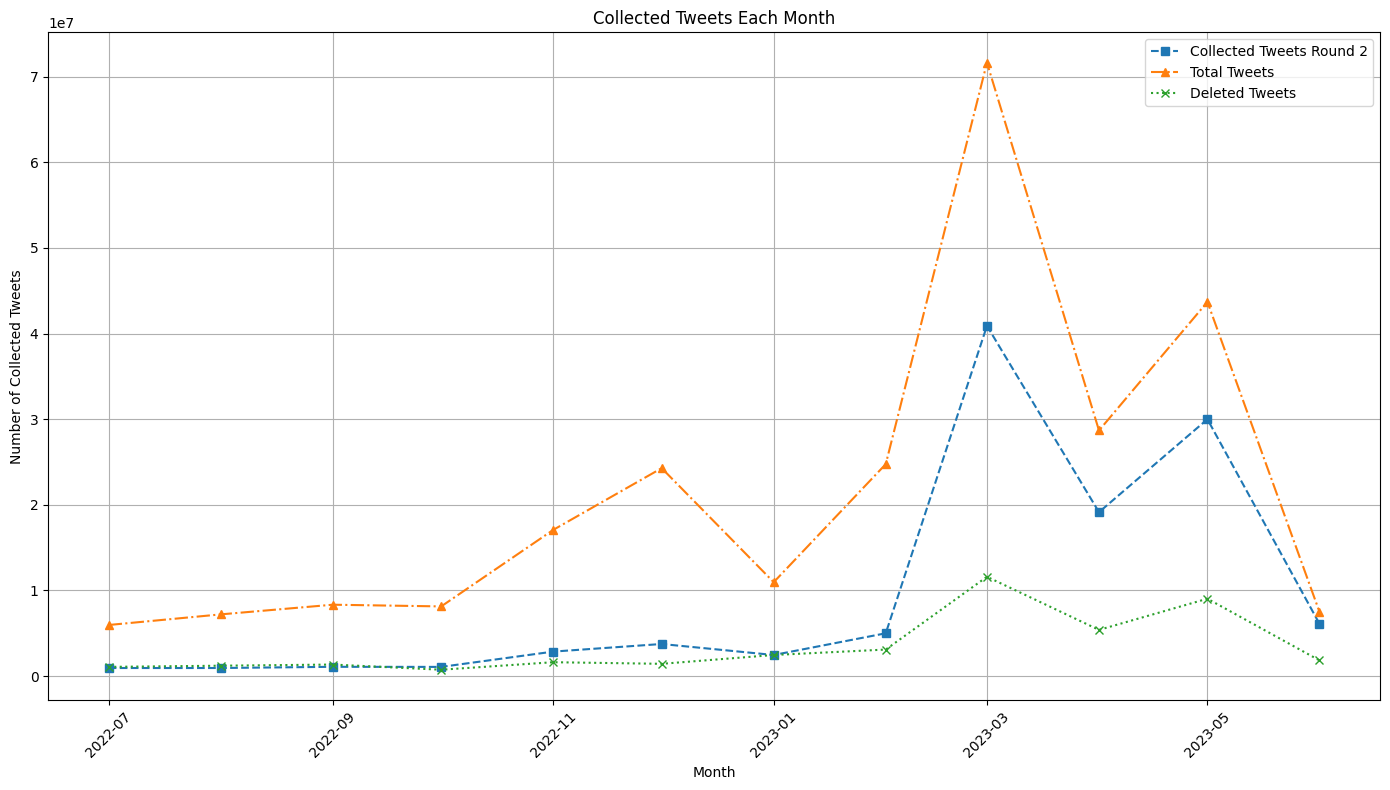

In [13]:
import matplotlib.pyplot as plt
import pandas as pd

# Data
months = [
    "2022-07", "2022-08", "2022-09", "2022-10", "2022-11",
    "2022-12", "2023-01", "2023-02", "2023-03", "2023-04",
    "2023-05", "2023-06"
]
collected_tweets = [
    935831, 935894, 1076747, 1065432, 2852889,
    3740714, 2455514, 4991962, 40898657, 19139319,
    29994243, 6101003
]
collected_tweets_2 = [
    2678526, 3077398, 3418584, 
    1875033, 4435711, 6255743, 6725383, 7724927, 
    50152597, 22389759, 35113429, 6520431
]
total_tweets = [
    5960000, 7200000, 8330000, 8130000, 17070000,
    24280000, 10960000, 24750000, 71640000, 28680000,
    43700000, 7500000
]
deleted_tweets = [
    1067712, 1204617, 1339878, 735862, 1613284, 
    1424986, 2457396, 3091672, 11592392,
    5389123, 9029356, 1827662
]

# Create a DataFrame
df = pd.DataFrame({
    'Months': pd.to_datetime(months),
    # 'Collected Tweets Round 1': collected_tweets,
    'Collected Tweets': collected_tweets_2,
    'Total Tweets': total_tweets,
    'Deleted Tweets': deleted_tweets
})

# Plot
plt.figure(figsize=(14, 8))
# plt.plot(df['Months'], df['Collected Tweets Round 1'], marker='o', label='Collected Tweets')
plt.plot(df['Months'], df['Collected Tweets'], marker='s', linestyle='--', label='Collected Tweets Round 2')
plt.plot(df['Months'], df['Total Tweets'], marker='^', linestyle='-.', label='Total Tweets')
plt.plot(df['Months'], df['Deleted Tweets'], marker='x', linestyle=':', label='Deleted Tweets')

plt.title('Collected Tweets Each Month')
plt.xlabel('Month')
plt.ylabel('Number of Collected Tweets')
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)
plt.tight_layout()

# Saving the figure
plt_path = "collected_tweets_plot.png"
plt.savefig(plt_path)
plt.show()


The following counts include only top 50 topics.

In [1]:
import pandas as pd
final_df = pd.read_csv('final_df_openailabels_totalcounts_3 - final_df_openailabels_totalcounts_3.csv')


In [3]:
df_first_50 = final_df.head(50)

In [19]:
first_20 = df_first_50.head(20)
first_20.iloc[:, 3:15].sum().to_list()

[504620,
 139141,
 137695,
 128751,
 349601,
 463981,
 184734,
 829582,
 2367933,
 1472120,
 3007050,
 696199]

In [4]:
monthly_sums = df_first_50.iloc[:, 3:15].sum()
monthly_sums

2022-07     802307
2022-08     209530
2022-09     216282
2022-10     198472
2022-11     538765
2022-12     676241
2023-01     294497
2023-02    1159891
2023-03    3570843
2023-04    2213077
2023-05    4614782
2023-06    1031753
dtype: int64

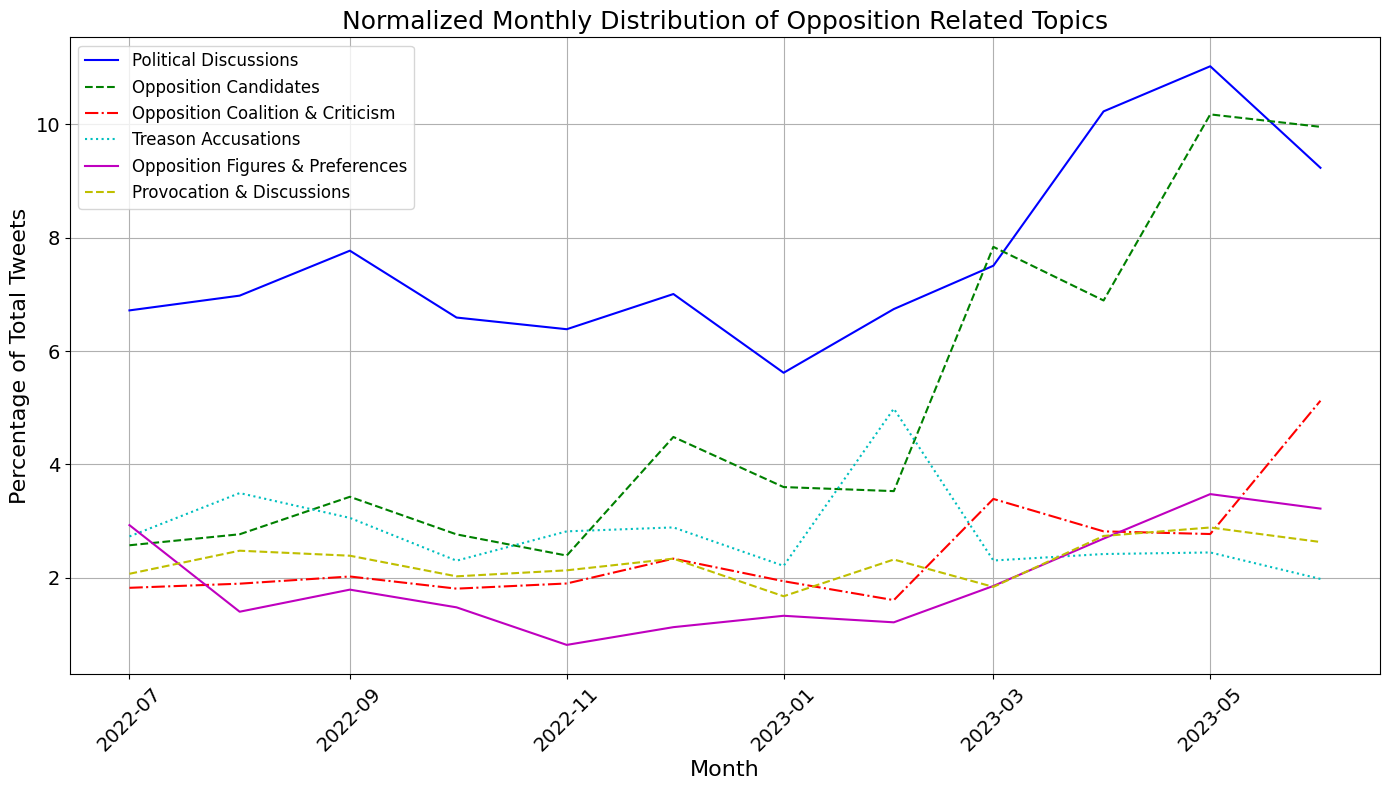

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

# Data for selected topics
topics_data_opposition = {
    "Political Discussions": [53886, 14618, 16803, 13080, 34397, 47370, 16541, 78178, 267957, 226288, 508562, 95234],
    "Opposition Candidates": [20664, 5803, 7419, 5493, 12898, 30330, 10607, 40947, 279830, 152506, 469403, 102686],
    "Opposition Coalition & Criticism": [14647, 3978, 4380, 3594, 10247, 15821, 5719, 18656, 121142, 62424, 128008, 52864],
    "Treason Accusations": [21915, 7325, 6614, 4572, 15198, 19545, 6516, 57812, 82373, 53581, 113010, 20452],
    "Opposition Figures & Preferences": [23511, 2942, 3879, 2940, 4413, 7655, 3924, 14118, 66353, 59582, 160481, 33245],
    "Provocation & Discussions": [16631, 5196, 5172, 4025, 11497, 15823, 4938, 26964, 65765, 60635, 133317, 27168]
}

topics_data_ruling_party = {
    "Political Discussions": [53886, 14618, 16803, 13080, 34397, 47370, 16541, 78178, 267957, 226288, 508562, 95234],
    "Erdogan & Nationalism": [84360, 16792, 19044, 18127, 46257, 58732, 23318, 60530, 211658, 136030, 289208, 55877],
    "Criticism of Political Figures": [17350, 5146, 4734, 3972, 13643, 19588, 5826, 74604, 126044, 60231, 127189, 34012],
    "Praise of Political Figures": [26757, 6540, 7845, 7376, 16936, 23521, 10002, 38996, 98144, 44795, 67799, 20854],
    "Erdogan's Election Chance": [8148, 1806, 2372, 2054, 5503, 10778, 3855, 9566, 100358, 36926, 146417, 20175]
}

topic_data_others= {
    "Political Discussions": [53886, 14618, 16803, 13080, 34397, 47370, 16541, 78178, 267957, 226288, 508562, 95234],
    "Religious Wishes": [49726, 14872, 13671, 12348, 38235, 42857, 16665, 105899, 145117, 121909, 161376, 41579],
    "Retirement System": [6745, 1236, 951, 4354, 5545, 18807, 10954, 18416, 144757, 80427, 53292, 35380],
    "Earthquake & Demands": [1410, 506, 339, 288, 8617, 3339, 2268, 156639, 153376, 22419, 21461, 6531],
    "Teachers & Demands": [18473, 11897, 6825, 12799, 38318, 25595, 22918, 9553, 76187, 55204, 57872, 29133]
}

# Convert to DataFrame for easier manipulation
df_topics = pd.DataFrame(topics_data_opposition, index=[
    "2022-07", "2022-08", "2022-09", "2022-10", "2022-11",
    "2022-12", "2023-01", "2023-02", "2023-03", "2023-04",
    "2023-05", "2023-06"
])

total_tweets_per_month_50 = [
802307, 209530, 216282, 198472, 538765, 676241, 294497, 1159891, 3570843, 2213077, 4614782, 1031753]

# Calculate total tweets per month across selected topics
# total_tweets_per_month = df_topics.sum(axis=1)

# Normalize the topic distributions
normalized_topics = df_topics.divide(total_tweets_per_month_50, axis=0) * 100

# Plot
plt.figure(figsize=(14, 8))
months = pd.to_datetime(df_topics.index)

# Customizing each plot with different styles
line_styles = ['-', '--', '-.', ':']
# markers = ['o', 's', '^', 'x', 'D', '*']
colors = ['b', 'g', 'r', 'c', 'm', 'y']

for i, (topic, style, color) in enumerate(zip(normalized_topics.columns, line_styles * 2, colors)):
    plt.plot(months, normalized_topics[topic], linestyle=style, color=color, label=topic)

plt.title('Normalized Monthly Distribution of Opposition Related Topics', fontsize=18)
plt.xlabel('Month', fontsize=16)
plt.ylabel('Percentage of Total Tweets', fontsize=16)
plt.xticks(rotation=45, fontsize=14)
plt.yticks(fontsize=14)
plt.legend(fontsize=12, loc='upper left')
plt.grid(True)
plt.tight_layout()

# Saving the figure
plt_path = "normalized_chp_selected_topics_distribution_with_styles.png"
plt.savefig(plt_path)
plt.show()

The following presents daily collected tweets

In [40]:
import pandas as pd
import glob
import re
from collections import defaultdict
import plotly.graph_objects as go

# Function to extract month from file path
def extract_month(file_path):
    match = re.search(r'(\d{4}-\d{2})', file_path)
    return match.group(1) if match else None

# Initialize a dictionary to store the count of tweets per day
daily_tweet_counts = defaultdict(int)

# Get a list of all CSV files
csv_files = glob.glob('../data/output/**/*.csv', recursive=True)

In [41]:
# Function to parse date
def parse_date(date_str):
    try:
        return datetime.datetime.strptime(date_str, "%Y-%m-%dT%H:%M:%S.%fZ")
    except ValueError:
        return pd.NaT

In [ ]:
# Process each file
for file in csv_files:
    try:
        df = pd.read_csv(file, usecols=['created_at'])
    except: 
        continue
    # Parse the dates in the 'created_at' column
    df['created_at'] = pd.to_datetime(df['created_at'], errors='coerce')
    # Drop rows with NaT values
    df.dropna(subset=['created_at'], inplace=True)
    # Group by date and count the number of tweets
    daily_counts = df.groupby(df['created_at'].dt.date).size()
    # Update the daily tweet counts
    for date, count in daily_counts.items():
        daily_tweet_counts[date] += count


In [43]:

# Convert the dictionary to a DataFrame
daily_tweets_df = pd.DataFrame(list(daily_tweet_counts.items()), columns=['Date', 'Tweet Count'])
# Sort the DataFrame by date
daily_tweets_df.sort_values('Date', inplace=True)

In [44]:
# Convert string to datetime object
start_date = pd.to_datetime('2022-06-01')

# Convert 'Date' column to Timestamp
daily_tweets_df['Date'] = pd.to_datetime(daily_tweets_df['Date'])

# Filter the DataFrame to start from June 2022
daily_tweets_df = daily_tweets_df[daily_tweets_df['Date'] >= start_date]


In [45]:
daily_tweets_df.head()

,Date,Tweet Count
76,2022-06-01,64
68,2022-06-02,65
167,2022-06-03,141
58,2022-06-04,72
97,2022-06-05,38


In [46]:
# Create the Plotly figure
fig = go.Figure(data=[
    go.Scatter(x=daily_tweets_df['Date'], y=daily_tweets_df['Tweet Count'], mode='lines')
])

# Update the layout
fig.update_layout(
    title='Daily Collected Tweets',
    xaxis_title='Date',
    yaxis_title='Number of Collected Tweets',
    hovermode='x'
)

# Show the figure
fig.show()


In [47]:
fig.write_html("figure_daily_collected_tweets_5.html")